In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('superstore_sales.csv')
df.head()
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10795,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10796,Yes,US-2018-147998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10797,Yes,US-2018-151127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [3]:
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [ ]:
# 2.Handle null values

df.duplicated().sum()
df.drop_duplicates(inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_17988\1607584484.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [6]:
df.isnull().sum()

Row ID             0
Order ID           0
Order Date       302
Ship Date        302
Ship Mode        302
Customer ID      302
Customer Name    302
Segment          302
Country          302
City             302
State            302
Postal Code      313
Region           302
Product ID       302
Category         302
Sub-Category     302
Product Name     302
Sales            302
Quantity         302
Discount         302
Profit           302
dtype: int64

In [ ]:
# Parse order dates and extract Year-Month.
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
df['Order Date'].dtype

dtype('<M8[us]')

In [10]:
df['Year-Month'] = df['Order Date'].dt.to_period('M')
df[['Order Date', 'Year-Month']].head()

,Order Date,Year-Month
0,2017-11-08,2017-11
1,2017-11-08,2017-11
2,2017-06-12,2017-06
3,2016-10-11,2016-10
4,2016-10-11,2016-10


In [11]:
df['Order Date'].isna().sum()

np.int64(302)

In [12]:
missing_dates = df[df['Order Date'].isna()]

missing_dates.head(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year-Month
9994,Person,Region,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9995,Anna Andreadi,West,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9996,Chuck Magee,East,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9997,Kelly Williams,Central,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9998,Cassandra Brandow,South,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9999,Returned,Order ID,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
10000,Yes,CA-2015-100762,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
10004,Yes,CA-2015-100867,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
10005,Yes,CA-2015-102652,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
10009,Yes,CA-2015-103373,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT


In [13]:
df['Order Date'].isna().mean() * 100

np.float64(2.9331779331779333)

In [14]:
valid_dates = df.dropna(subset=['Order Date']).copy()

In [15]:
valid_dates['Year-Month'] = (
    valid_dates['Order Date'].dt.to_period('M')
)

In [18]:
monthly_sales = df.groupby('Year-Month')['Sales'].sum()

print(monthly_sales)

Year-Month
2015-01     14236.8950
2015-02      4519.8920
2015-03     55691.0090
2015-04     28295.3450
2015-05     23648.2870
2015-06     34595.1276
2015-07     33946.3930
2015-08     27909.4685
2015-09     81777.3508
2015-10     31453.3930
2015-11     78628.7167
2015-12     69545.6205
2016-01     18174.0756
2016-02     11951.4110
2016-03     38726.2520
2016-04     34195.2085
2016-05     30131.6865
2016-06     24797.2920
2016-07     28765.3250
2016-08     36898.3322
2016-09     64595.9180
2016-10     31404.9235
2016-11     75972.5635
2016-12     74919.5212
2017-01     18542.4910
2017-02     22978.8150
2017-03     51715.8750
2017-04     38750.0390
2017-05     56987.7280
2017-06     40344.5340
2017-07     39261.9630
2017-08     31115.3743
2017-09     73410.0249
2017-10     59687.7450
2017-11     79411.9658
2017-12     96999.0430
2018-01     43971.3740
2018-02     20301.1334
2018-03     58872.3528
2018-04     36521.5361
2018-05     44261.1102
2018-06     52981.7257
2018-07     45264.4160


In [19]:
# 3. Group by Product Category, Region, and
# Customer Segment to compute aggregate Sales & Profit.

category_analysis = df.groupby(
    ['Category', 'Region', 'Segment']
)[['Sales', 'Profit']].sum()

print(category_analysis)

                                           Sales      Profit
Category        Region  Segment                             
Furniture       Central Consumer      86229.2190  -3994.4342
                        Corporate     52085.6018   2321.9939
                        Home Office   25482.3430  -1198.6091
                East    Consumer     114211.8020   2038.1122
                        Corporate     64209.0460    342.1257
                        Home Office   29870.3560    665.9279
                South   Consumer      70800.2040   4616.7326
                        Corporate     29645.0315    952.0303
                        Home Office   16853.4485   1202.4432
                West    Consumer     119808.0870   4330.6680
                        Corporate     83080.1065   3968.6659
                        Home Office   49724.5500   3205.6164
Office Supplies Central Consumer      93111.4790   2583.1432
                        Corporate     41137.7010     99.2948
                        

In [22]:
## 4. Plot monthly sales velocity and discount-vs-profit scatter plots.

monthly_sales = df.groupby(
    df['Order Date'].dt.to_period('M')
)['Sales'].sum()

monthly_sales.index = monthly_sales.index.to_timestamp()

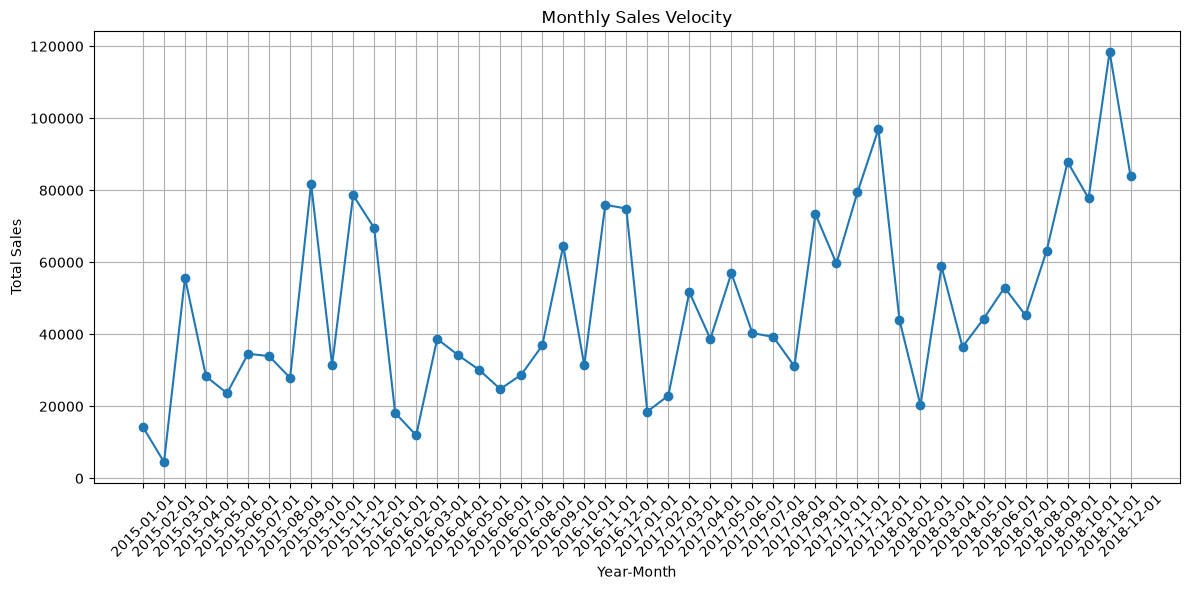

In [23]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_sales.index.astype(str),
         monthly_sales.values,
         marker='o')

plt.title('Monthly Sales Velocity')
plt.xlabel('Year-Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
# Discount-vs-Profit scatter plots

df[['Discount', 'Profit']].head()

,Discount,Profit
0,0.00,41.9136
1,0.00,219.5820
2,0.00,6.8714
3,0.45,-383.0310
4,0.20,2.5164


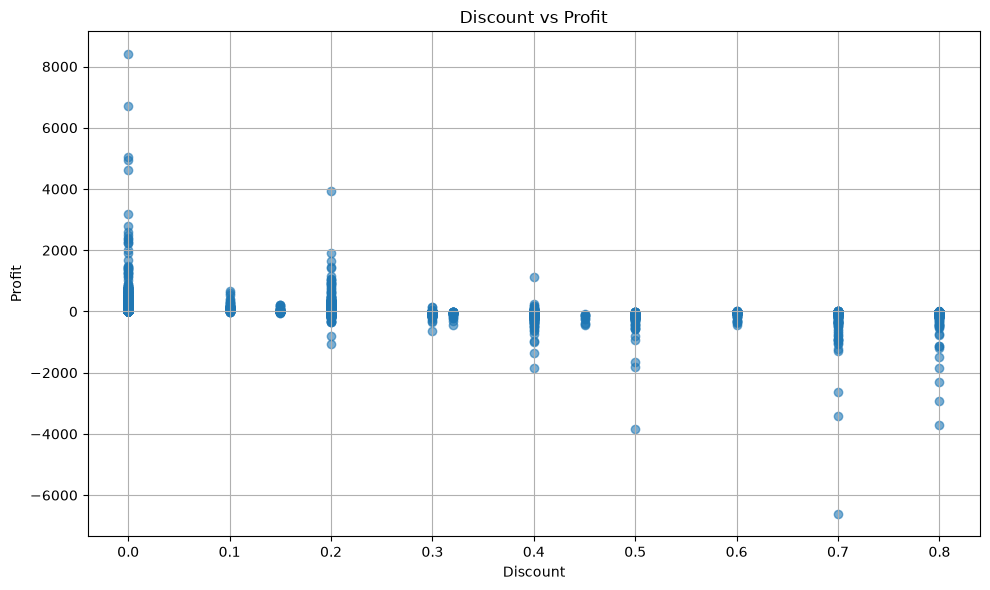

In [26]:
# Discount-vs-Profit scatter plots

plt.figure(figsize=(10, 6))

plt.scatter(df['Discount'], df['Profit'], alpha=0.6)

plt.title('Discount vs Profit')
plt.xlabel('Discount')
plt.ylabel('Profit')

plt.grid(True)

plt.tight_layout()
plt.show()